# Match simulation demo

Ball-by-ball T20 Monte Carlo simulation (`criiq_models.simulate.engine`), the two genetic-algorithm optimizers (`ga_bowling`, `ga_batting`), and the win-probability chart with key-moments annotation (`keymoments`, `report`).

Re-run after any change to `simulate/*.py` -- like `model_comparison.ipynb`, this is a snapshot of a real run against the live DB, not hardcoded output. Requires data-collection's `criiq.db` and a trained win-probability model (`criiq-data winprob`) for the chosen `(format, gender)`.

In [1]:
%matplotlib inline

from criiq_models.db import connect
from criiq_models.recommend.score import RecommendationScorer
from criiq_models.selection.optimize import select_xi
from criiq_models.features.common import bowling_capable
from criiq_models.features.current import resolve_role
from criiq_models.venues import resolve_venue
from criiq_models.simulate.outcomes import build_outcome_model, build_player_profiles
from criiq_models.simulate.winprob_reader import WinProbLookup
from criiq_models.simulate.engine import simulate_match
from criiq_models.simulate.keymoments import detect_key_moments
from criiq_models.simulate.report import plot_win_probability, aggregate_win_probability
from criiq_models.simulate.scorecard import batting_scorecard, bowling_scorecard, coach_perspective, render_scorecard_text
from criiq_models.simulate.ga_bowling import optimize_bowling_rotation
from criiq_models.simulate.ga_batting import optimize_batting_order
from criiq_models.roster import team_pool

FORMAT, GENDER = "T20", "female"
TEAM1, TEAM2 = "Nepal", "India"
VENUE_NAME = "DY Patil"  # e.g. "Wankhede Stadium" -- conditions batters' setting/chasing strike rate there

# RNG seed for the Monte Carlo simulation and both GAs below. Real cricket
# (and a real Monte Carlo/GA) never repeats itself -- leave this as `None` to
# get a genuinely different match/search every time you run this notebook,
# same as `criiq_models.cli simulate`'s own default. Set a fixed integer only
# if you specifically want to reproduce one exact run again (e.g. to debug a
# particular result).
SEED = None

conn = connect()
VENUE_ID = resolve_venue(conn, VENUE_NAME)[0] if VENUE_NAME else None

## Build two Playing XIs -- the model's own optimal recommendation by default, or your own hand-picked XI

Set `TEAM1_CUSTOM_PLAYERS`/`TEAM2_CUSTOM_PLAYERS` below to a list of player names to override that side's automatic pick with your own choice (mirrors `analyze-xi`'s "coach's own hand-picked XI" idea) -- leave as `None` to use `select_xi`'s provably-optimal XI (the same MILP-based selection `recommend` uses) against the given opponent. Either side can be overridden independently, so you can test "our optimal XI vs a specific opposition XI we name" just as easily as "optimal vs optimal".

In [2]:
# Set either of these to a list of player names to hand-pick that side's XI
# instead of using the model's own optimal recommendation, e.g.:
# TEAM1_CUSTOM_PLAYERS = ["S Mandhana", "Shafali Verma", "D Hemalatha", "JI Rodrigues", "H Kaur",
#                         "S Meghana", "DB Sharma", "P Vastrakar", "YH Bhatia", "M Mani", "N Shree Charani"]
TEAM1_CUSTOM_PLAYERS = None
TEAM2_CUSTOM_PLAYERS = None


def _resolve_name(name):
    matches = [dict(r) for r in conn.execute(
        "SELECT player_id, canonical_name FROM players WHERE canonical_name LIKE ? LIMIT 5",
        (f"%{name}%",)).fetchall()]
    if len(matches) != 1:
        raise ValueError(f"{name!r} resolved to {len(matches)} players: {matches} -- be more specific")
    return matches[0]["player_id"]


def resolve_xi(team_name, opponent_name, custom_players):
    """`custom_players` (list of names) -> that exact XI, in the order given.
    `None` -> the model's own optimal XI (`select_xi`'s provably-optimal MILP
    pick) against `opponent_name`, exactly what `recommend` returns.

    Raises immediately with a clear message if the team's eligible pool is
    too thin to field 11 (e.g. a team with little/no recorded international
    data for this format/gender) -- real bug found live: an empty XI here
    silently produced a 0-bowler pool downstream, which only surfaced as a
    confusing "no eligible bowler" crash deep inside the simulator instead
    of a clear error at the actual source.
    """
    if custom_players:
        if len(custom_players) != 11:
            raise ValueError(f"{team_name}: need exactly 11 players, got {len(custom_players)}")
        return [_resolve_name(n) for n in custom_players], "hand-picked"
    pool_ids = team_pool(conn, team_name, FORMAT, GENDER)
    if not pool_ids:
        raise ValueError(f"no eligible players found for team={team_name!r} "
                          f"(format={FORMAT}, gender={GENDER}) -- pick a different team")
    scorer = RecommendationScorer(conn, FORMAT, GENDER)
    pool = scorer.score_many(pool_ids, opponent_name)
    xi = select_xi(pool)["xi"]
    if len(xi) != 11:
        raise ValueError(f"{team_name}: only {len(xi)} players could be selected into an XI "
                          f"(pool of {len(pool_ids)} eligible players is too thin)")
    return [p["player_id"] for p in xi], "model-optimal"


team1_ids, team1_method = resolve_xi(TEAM1, TEAM2, TEAM1_CUSTOM_PLAYERS)
team2_ids, team2_method = resolve_xi(TEAM2, TEAM1, TEAM2_CUSTOM_PLAYERS)


def bowling_pool(ids):
    return [pid for pid in ids if bowling_capable(resolve_role(conn, pid, FORMAT)[0])]


team1 = {"name": TEAM1, "batting_order": team1_ids, "bowling_pool": bowling_pool(team1_ids)}
team2 = {"name": TEAM2, "batting_order": team2_ids, "bowling_pool": bowling_pool(team2_ids)}


def _name_of(pid):
    row = conn.execute("SELECT canonical_name FROM players WHERE player_id=?", (pid,)).fetchone()
    return dict(row)["canonical_name"] if row else pid


names_preview = {pid: _name_of(pid) for pid in team1_ids + team2_ids}
print(f"{TEAM1} XI ({team1_method}):", [names_preview[p] for p in team1_ids])
print(f"{TEAM2} XI ({team2_method}):", [names_preview[p] for p in team2_ids])
print("bowling-capable:", len(team1["bowling_pool"]), "/", len(team2["bowling_pool"]))
for label, side in ((TEAM1, team1), (TEAM2, team2)):
    if len(side["bowling_pool"]) < 5:
        print(f"warning: {label} has only {len(side['bowling_pool'])} bowling-capable players -- "
              f"may not be able to legally complete 20 overs (max 4 overs/bowler, no consecutive "
              f"overs, rulebook-cricket.md sec 2)")

Nepal XI (model-optimal): ['SR Magar', 'Samjhana Khadka', 'RC Belbashi', 'Puja Mahato', 'I Barma', 'Sangita Rai', 'M Upadhayay', 'Riya Sharma', 'K Dangol', 'A Karmacharya', 'R Chaudhary']
India XI (model-optimal): ['S Mandhana', 'Shafali Verma', 'D Hemalatha', 'H Kaur', 'JI Rodrigues', 'S Meghana', 'YH Bhatia', 'DB Sharma', 'DP Vaidya', 'M Mani', 'Renuka Singh']
bowling-capable: 10 / 8


## Baseline simulation vs a "player goes out" scenario

In [3]:
outcome_model = build_outcome_model(conn, FORMAT, GENDER, team1_ids, team2_ids)
batter_profiles, bowler_profiles = build_player_profiles(
    conn, FORMAT, team1_ids, team2_ids, TEAM1, TEAM2, venue_id=VENUE_ID)
winprob = WinProbLookup.load(FORMAT, GENDER)

N_REPS = 30
baseline_reps = simulate_match(team1, team2, "team1", outcome_model, batter_profiles, bowler_profiles,
                                winprob, n_reps=N_REPS, rng_seed=SEED)

# Force team1's opener out first ball -- the concrete "what happens if this
# player goes out here" scenario.
forced = {"player_id": team1_ids[0], "over": 0, "ball": 1}
scenario_reps = simulate_match(team1, team2, "team1", outcome_model, batter_profiles, bowler_profiles,
                                winprob, forced_dismissal=forced, n_reps=N_REPS, rng_seed=SEED)

import pandas as pd
pd.Series([r["winner"] for r in baseline_reps]).value_counts(normalize=True) * 100

ImportError: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - `Import pyarrow` failed. pyarrow is required for parquet support. Use pip or conda to install the pyarrow package.
 - `Import fastparquet` failed. fastparquet is required for parquet support. Use pip or conda to install the fastparquet package.

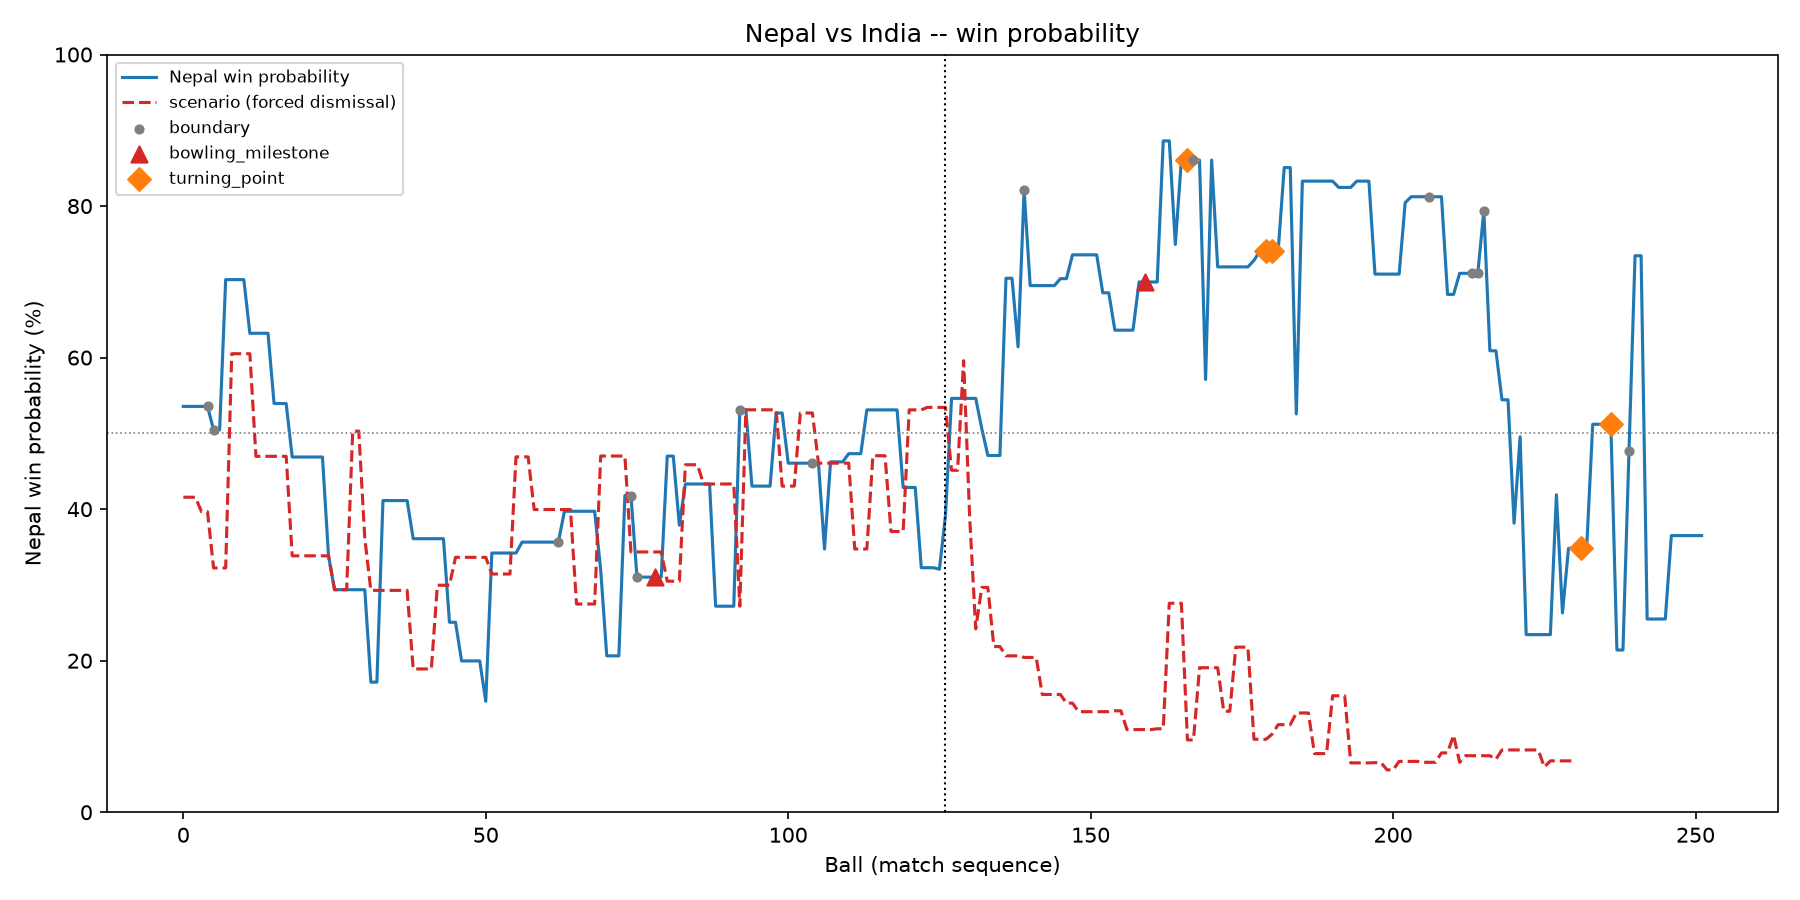

In [ ]:
rep = baseline_reps[0]
scenario_rep = scenario_reps[0]
combined_log = pd.concat([rep["first_innings_log"], rep["second_innings_log"]], ignore_index=True)
names = {pid: (conn.execute("SELECT canonical_name FROM players WHERE player_id=?", (pid,)).fetchone() or {"canonical_name": pid})["canonical_name"]
         for pid in team1_ids + team2_ids}
key_moments = detect_key_moments(combined_log, name_map=names)

plot_win_probability(rep, "artifacts/simulation/notebook_demo.png", scenario_rep=scenario_rep, key_moments=key_moments)
from IPython.display import Image
Image("artifacts/simulation/notebook_demo.png")

In [ ]:
for m in key_moments:
    print(f"inn{m['innings']} {m['over']}.{m['ball']} -- {m['description']}")

inn1 0.5 -- Samjhana Khadka hits a 4 (score 5/0)
inn1 0.6 -- Samjhana Khadka hits a 4 (score 9/0)
inn1 10.3 -- K Kunwar hits a 4 (score 45/3)
inn1 12.3 -- K Kunwar hits a 4 (score 58/4)
inn1 12.4 -- K Kunwar hits a 4 (score 62/4)
inn1 13.1 -- DB Sharma takes their 3rd wicket (3-for)
inn1 15.3 -- Sangita Rai hits a 4 (score 79/5)
inn1 17.3 -- Sangita Rai hits a 4 (score 89/6)
inn2 2.2 -- JI Rodrigues hits a 4 (score 6/3)
inn2 5.4 -- A Karmacharya takes their 3rd wicket (3-for)
inn2 6.5 -- DB Sharma hits a 4 (score 28/4)
inn2 6.5 -- Big swing: 4 by DB Sharma off RC Belbashi (+29.0pp win probability)
inn2 6.6 -- DB Sharma hits a 4 (score 32/4)
inn2 8.6 -- Big swing: bye by DB Sharma off RC Belbashi (+32.5pp win probability)
inn2 9.1 -- Big swing: 0 by DB Sharma off M Upadhayay (-30.7pp win probability)
inn2 13.3 -- DB Sharma hits a 4 (score 57/5)
inn2 14.4 -- DB Sharma hits a 4 (score 66/5)
inn2 14.5 -- DB Sharma hits a 4 (score 70/5)
inn2 14.6 -- DB Sharma hits a 4 (score 74/5)
inn2 17.4

## Scorecard -- both innings, batting + the opposing bowling figures

Generic by construction (operates purely on the ball log + a name lookup), so this works identically for any two teams/genders `team1`/`team2` above are set to.

In [ ]:
first_bat = batting_scorecard(rep["first_innings_log"], names)
first_bowl = bowling_scorecard(rep["first_innings_log"], names)
print(render_scorecard_text(rep["batting_first_team"], first_bat, first_bowl, rep["bowling_first_team"]))

Nepal batting:
  batter                  runs  balls      SR  
  SR Magar                   2      9    22.2  (out)
  Samjhana Khadka           15     18    83.3  (out)
  RC Belbashi                1      7    14.3  (out)
  Puja Mahato               11     22    50.0  (out)
  K Kunwar                  22     20   110.0  (out)  -- Top scorer (22 off 20)
  Roma Thapa                14     17    82.4  (out)
  Sangita Rai               18     18   100.0  (out)
  M Upadhayay                4      6    66.7  (out)
  Riya Sharma                1      2    50.0  (not out)
  K Dangol                   1      2    50.0  (not out)

India bowling:
  bowler                  overs  runs  wkts   econ
  M Mani                    3.0    13     1   4.33
  RP Yadav                  3.0    11     1   3.67
  JI Rodrigues              4.0    23     0   5.75
  DB Sharma                 4.0    17     3   4.25  -- Pick of the bowlers (3-for-17)
  Shafali Verma             1.0     6     0   6.00
  D Hemalatha  

In [ ]:
second_bat = batting_scorecard(rep["second_innings_log"], names)
second_bowl = bowling_scorecard(rep["second_innings_log"], names)
print(render_scorecard_text(rep["bowling_first_team"], second_bat, second_bowl, rep["batting_first_team"]))

India batting:
  batter                  runs  balls      SR  
  S Mandhana                 0      2     0.0  (out)
  H Kaur                    14     24    58.3  (out)
  Shafali Verma              0      4     0.0  (out)
  D Hemalatha                0      2     0.0  (out)
  JI Rodrigues               7     10    70.0  (out)
  DB Sharma                 41     40   102.5  (out)  -- Top scorer (41 off 40)
  S Meghana                 18     21    85.7  (out)
  YH Bhatia                  1      6    16.7  (out)
  RP Yadav                   6      6   100.0  (not out)
  M Mani                     2      5    40.0  (not out)

Nepal bowling:
  bowler                  overs  runs  wkts   econ
  K Kunwar                  4.0    28     1   7.00
  A Karmacharya             3.0     8     3   2.67  -- Pick of the bowlers (3-for-8)
  RC Belbashi               4.0    20     1   5.00
  M Upadhayay               4.0    17     0   4.25
  Sangita Rai               3.0    12     1   4.00
  K Dangol      

## Bowling rotation -- who bowled each over, and each phase

Distinct from the scorecard's per-bowler match totals: the actual over-by-over sequence, plus a per-phase (powerplay/middle/death) breakdown -- the real basis for judging whether a rotation matched real captaincy (specialists bowling their own phase) rather than an arbitrary spread.

In [ ]:
from criiq_models.simulate.scorecard import bowling_phase_summary, bowling_rotation, render_bowling_rotation_text

first_rotation = bowling_rotation(rep["first_innings_log"], names)
print(render_bowling_rotation_text(rep["bowling_first_team"], first_rotation, bowling_phase_summary(first_rotation)))

India bowling rotation (over by over):
  over  1 (powerplay): M Mani                6b  9r  0w
  over  2 (powerplay): RP Yadav              6b  3r  0w
  over  3 (powerplay): M Mani                6b  2r  1w
  over  4 (powerplay): RP Yadav              6b  1r  1w
  over  5 (powerplay): M Mani                6b  2r  0w
  over  6 (powerplay): RP Yadav              6b  7r  0w
  over  7 (middle   ): JI Rodrigues          6b  1r  0w
  over  8 (middle   ): DB Sharma             6b  2r  1w
  over  9 (middle   ): JI Rodrigues          6b  5r  0w
  over 10 (middle   ): DB Sharma             6b  6r  0w
  over 11 (middle   ): JI Rodrigues          6b  7r  0w
  over 12 (middle   ): DB Sharma             6b  5r  1w
  over 13 (middle   ): JI Rodrigues          6b  10r  0w
  over 14 (middle   ): DB Sharma             6b  4r  1w
  over 15 (middle   ): Shafali Verma         6b  6r  0w
  over 16 (death    ): D Hemalatha           6b  8r  0w
  over 17 (death    ): H Kaur                6b  2r  0w
  over 1

In [ ]:
second_rotation = bowling_rotation(rep["second_innings_log"], names)
print(render_bowling_rotation_text(rep["batting_first_team"], second_rotation, bowling_phase_summary(second_rotation)))

Nepal bowling rotation (over by over):
  over  1 (powerplay): K Kunwar              6b  0r  1w
  over  2 (powerplay): A Karmacharya         6b  1r  2w
  over  3 (powerplay): K Kunwar              6b  9r  0w
  over  4 (powerplay): A Karmacharya         6b  3r  0w
  over  5 (powerplay): K Kunwar              6b  4r  0w
  over  6 (powerplay): A Karmacharya         6b  4r  1w
  over  7 (middle   ): RC Belbashi           6b  11r  0w
  over  8 (middle   ): M Upadhayay           6b  2r  0w
  over  9 (middle   ): RC Belbashi           6b  6r  1w
  over 10 (middle   ): M Upadhayay           6b  3r  0w
  over 11 (middle   ): RC Belbashi           6b  2r  0w
  over 12 (middle   ): M Upadhayay           6b  5r  0w
  over 13 (middle   ): RC Belbashi           6b  1r  0w
  over 14 (middle   ): M Upadhayay           6b  7r  0w
  over 15 (middle   ): K Kunwar              6b  15r  0w
  over 16 (death    ): Sangita Rai           6b  4r  0w
  over 17 (death    ): K Dangol              6b  4r  1w
  over 

## Coach's perspective

Narrated from either named side -- set `COACH_TEAM` to `TEAM1` or `TEAM2`.

In [ ]:
COACH_TEAM = TEAM1
print(coach_perspective(rep, key_moments, COACH_TEAM, name_map=names))

Nepal set the total: 99/8 off 20 overs, leaving India to chase 100.
With the ball: A Karmacharya takes their 3rd wicket (3-for).
The moment that decided it: Big swing: 1 by M Mani off K Dangol (+47.9pp win probability) (innings 2, over 18.3).
Result: A win for Nepal (Nepal won the match).


## Monte Carlo win-probability band across all reps

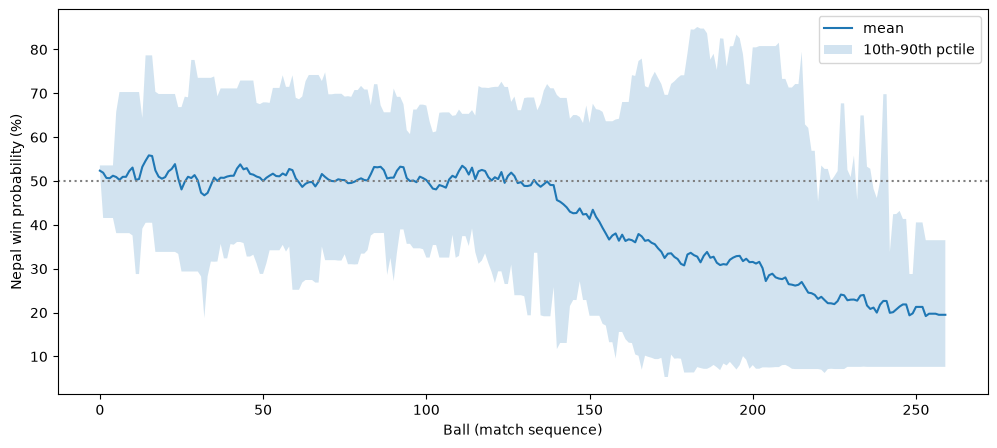

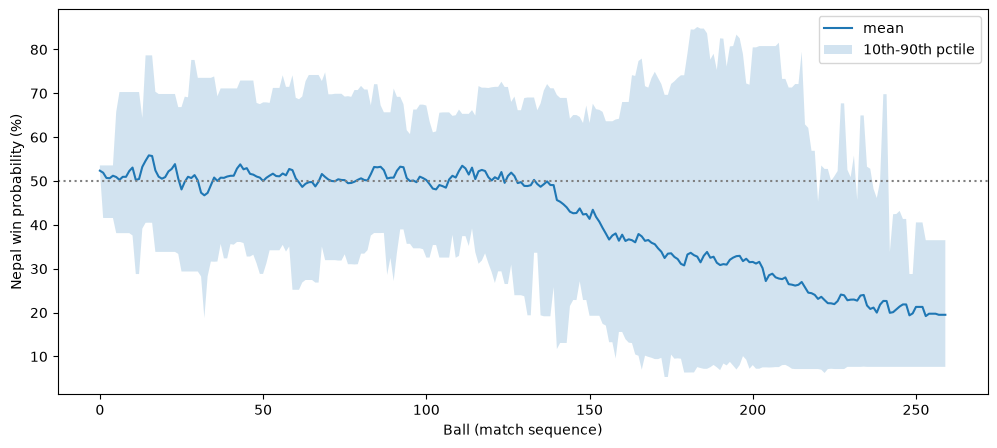

In [ ]:
import matplotlib.pyplot as plt

band = aggregate_win_probability(baseline_reps)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(band["match_ball_index"], band["mean"] * 100, label="mean")
ax.fill_between(band["match_ball_index"], band["p10"] * 100, band["p90"] * 100, alpha=0.2, label="10th-90th pctile")
ax.axhline(50, linestyle=":", color="gray")
ax.set_xlabel("Ball (match sequence)")
ax.set_ylabel(f"{team1['name']} win probability (%)")
ax.legend()
fig

## Genetic algorithms: bowling rotation + batting order, with convergence

recognized bowlers (default full quota): ['M Mani', 'RP Yadav', 'N Shree Charani', 'Shafali Verma', 'H Kaur']
expected runs conceded: 108.13
overs per bowler: {'M Mani': 4, 'RP Yadav': 4, 'N Shree Charani': 4, 'Shafali Verma': 4, 'H Kaur': 3, 'JI Rodrigues': 1}


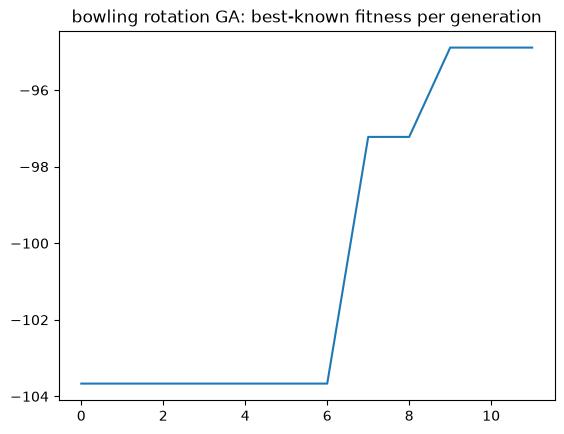

In [ ]:
# The up to 5 recognized specialist bowlers (role_bucket == "bowler") default
# to taking the full quota between them, 4 overs each -- real captaincy, not
# an even spread across every bowling-capable player. See ga_bowling.py's
# primary_bowlers docstring for how/when others still get introduced.
def _primary_bowlers(pool):
    specialists = [p for p in pool if resolve_role(conn, p, FORMAT)[0] == "bowler"]
    if len(specialists) >= 5:
        return specialists[:5]
    others = [p for p in pool if p not in specialists]
    return specialists + others[:5 - len(specialists)]

primary_bowlers = _primary_bowlers(team2["bowling_pool"])
print("recognized bowlers (default full quota):", [names_preview.get(b, b) for b in primary_bowlers])

bowling_result = optimize_bowling_rotation(team2["bowling_pool"], team1_ids, outcome_model, batter_profiles,
                                           bowler_profiles, primary_bowlers=primary_bowlers,
                                           pop_size=12, generations=12, n_reps=3, rng_seed=SEED)
print("expected runs conceded:", bowling_result["expected_runs_conceded"])
print("overs per bowler:", {names_preview.get(b, b): n for b, n in bowling_result["overs_per_bowler"].items()})
plt.plot(bowling_result["fitness_history"]); plt.title("bowling rotation GA: best-known fitness per generation"); plt.show()

openers: ['SR Magar', 'Samjhana Khadka']
top/middle order: ['Puja Mahato', 'RC Belbashi', 'K Kunwar', 'Roma Thapa']
tail: ['Sangita Rai', 'Riya Sharma', 'A Karmacharya', 'M Upadhayay', 'K Dangol']
expected score: 106.767
order: ['SR Magar', 'Samjhana Khadka', 'Puja Mahato', 'RC Belbashi', 'K Kunwar', 'Roma Thapa', 'Sangita Rai', 'Riya Sharma', 'A Karmacharya', 'M Upadhayay', 'K Dangol']


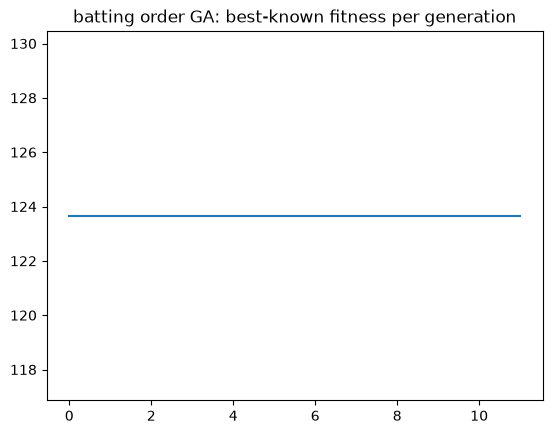

In [ ]:
# Batting order is searched in role bands, not one free-for-all permutation:
# openers (can still interchange 1 vs 2), top/middle order (rotate among
# themselves), tail/specialist bowlers (rotate among themselves) -- see
# ga_batting.py's batting_groups docstring.
def _batting_groups(ids):
    rows = [(pid, *resolve_role(conn, pid, FORMAT)) for pid in ids]
    rows.sort(key=lambda r: r[3] if r[3] is not None else float("inf"))
    openers = [r[0] for r in rows[:2]]
    rest = rows[2:]
    tail = [r[0] for r in rest if r[1] == "bowler"]
    top_middle = [r[0] for r in rest if r[1] != "bowler"]
    return [g for g in (openers, top_middle, tail) if g]

batting_groups = _batting_groups(team1_ids)
for label, group in zip(["openers", "top/middle order", "tail"], batting_groups):
    print(f"{label}: {[names_preview.get(p, p) for p in group]}")

batting_result = optimize_batting_order(batting_groups, team2["bowling_pool"], outcome_model, batter_profiles,
                                        bowler_profiles, pop_size=12, generations=12, n_reps=3, rng_seed=SEED)
print("expected score:", batting_result["expected_score"])
print("order:", [names_preview.get(p, p) for p in batting_result["batting_order"]])
plt.plot(batting_result["fitness_history"]); plt.title("batting order GA: best-known fitness per generation"); plt.show()